In [3]:
# Week 4 - Day 3: Regression Analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Reproducible results
np.random.seed(42)

print("Week 4 Day 3: Regression Analysis")
print("Libraries imported successfully!")

Week 4 Day 3: Regression Analysis
Libraries imported successfully!


In [2]:
%pip install scikit-learn

   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.3 MB 9.4 MB/s eta 0:00:01
   ------- -------------------------------- 1.5/8.3 MB 11.9 MB/s eta 0:00:01
   ------------ --------------------------- 2.6/8.3 MB 15.2 MB/s eta 0:00:01
   --------------- ------------------------ 3.2/8.3 MB 15.8 MB/s eta 0:00:01
   --------------- ------------------------ 3.2/8.3 MB 15.8 MB/s eta 0:00:01
   ------------------- -------------------- 3.9/8.3 MB 14.0 MB/s eta 0:00:01
   -------------------- ------------------- 4.2/8.3 MB 12.3 MB/s eta 0:00:01
   ---------------------- ----------------- 4.6/8.3 MB 12.2 MB/s eta 0:00:01
   ----------------------- ---------------- 4.8/8.3 MB 11.1 MB/s eta 0:00:01
   ------------------------ --------------- 5.1/8.3 MB 10.1 MB/s eta 0:00:01
   ------------------------ --------------- 5.1/8.3 MB 10.1 MB/s eta 0:00:01
   -------------------------- ------------- 5.5/8.3 MB 9.5 MB/s eta 0:00:01
   ------


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
data = {
    "Hours_Studied": [2, 3, 4, 5, 6, 7, 8, 2, 5, 9,
                      3, 6, 7, 4, 8, 1, 9, 5, 6, 10],
    "Attendance": [60, 65, 70, 75, 80, 85, 90, 55, 78, 95,
                   62, 82, 88, 72, 92, 50, 96, 76, 84, 98],
    "Previous_Score": [55, 60, 65, 70, 72, 78, 85, 50, 68, 90,
                       58, 75, 80, 63, 88, 45, 92, 70, 76, 95],
    "Final_Score": [48, 55, 60, 65, 70, 78, 85, 45, 66, 92,
                    52, 74, 82, 59, 88, 40, 95, 68, 76, 98]
}

df = pd.DataFrame(data)

print("Dataset Preview:")
display(df.head())

print("\nDataset Shape:", df.shape)
print("\nSummary Statistics:")
display(df.describe())

Dataset Preview:


,Hours_Studied,Attendance,Previous_Score,Final_Score
0,2,60,55,48
1,3,65,60,55
2,4,70,65,60
3,5,75,70,65
4,6,80,72,70



Dataset Shape: (20, 4)

Summary Statistics:


,Hours_Studied,Attendance,Previous_Score,Final_Score
count,20.000000,20.000000,20.000000,20.000000
mean,5.500000,77.650000,71.750000,69.800000
std,2.564946,14.012307,14.137948,17.052859
min,1.000000,50.000000,45.000000,40.000000
25%,3.750000,68.750000,62.250000,58.000000
50%,5.500000,79.000000,71.000000,69.000000
75%,7.250000,88.500000,81.250000,82.750000
max,10.000000,98.000000,95.000000,98.000000


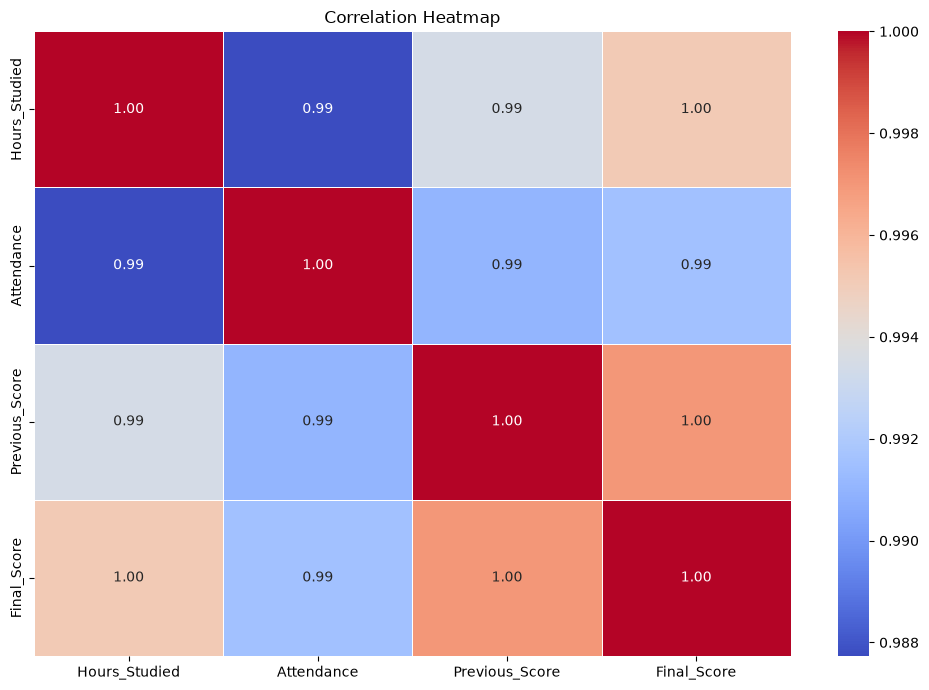

In [5]:
# Correlation Heatmap

plt.figure(figsize=(10, 7))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

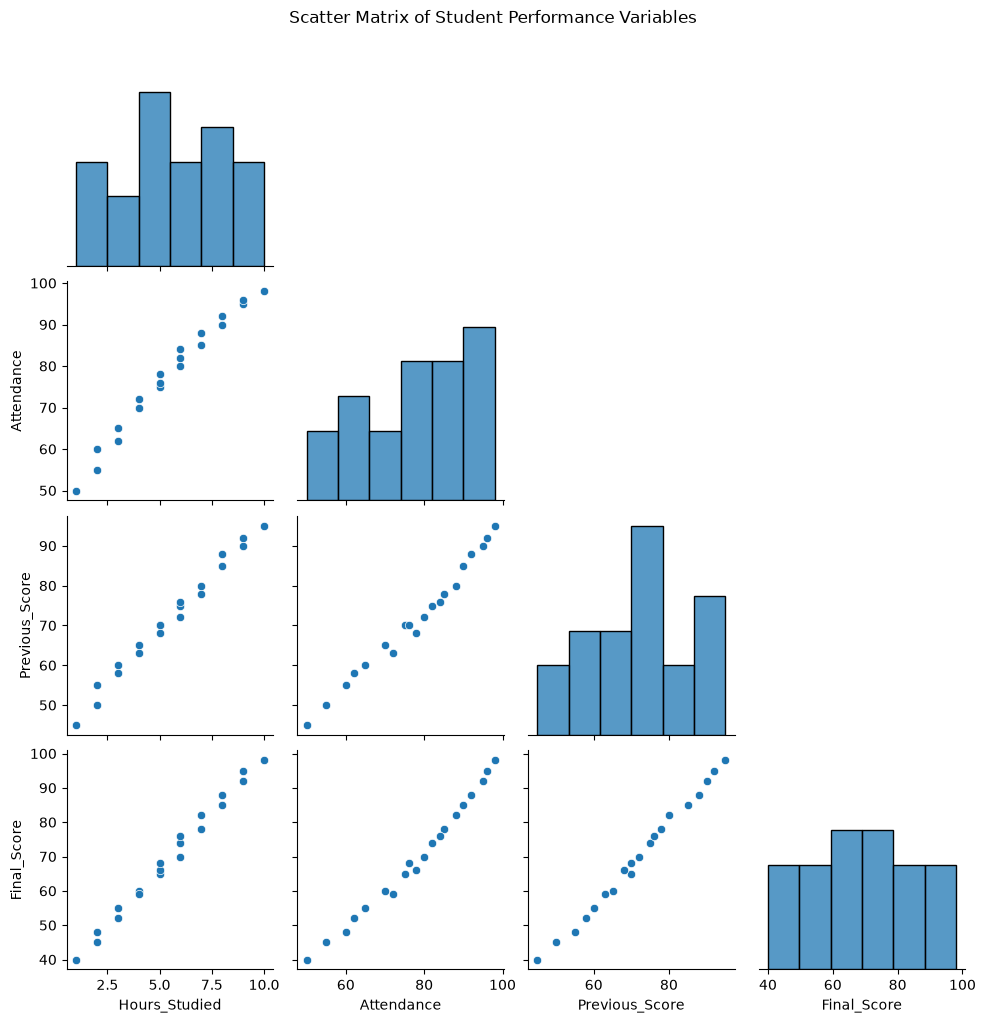

In [6]:
# Scatter Matrix

sns.pairplot(
    df,
    diag_kind="hist",
    corner=True
)

plt.suptitle("Scatter Matrix of Student Performance Variables", y=1.02)
plt.show()

In [7]:
# Linear Regression Model

X = df[["Hours_Studied", "Attendance", "Previous_Score"]]
y = df["Final_Score"]

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict final scores
y_pred = model.predict(X_test)

print("Model trained successfully!")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

results = pd.DataFrame({
    "Actual Score": y_test.values,
    "Predicted Score": np.round(y_pred, 2)
})

display(results)

Model trained successfully!
Training samples: 16
Testing samples: 4


,Actual Score,Predicted Score
0,48,47.81
1,68,67.09
2,40,36.90
3,55,54.15


In [8]:
# Model Evaluation Metrics

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"R² Score: {r2:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")

R² Score: 0.9736
Mean Absolute Error (MAE): 1.2597
Root Mean Squared Error (RMSE): 1.6708


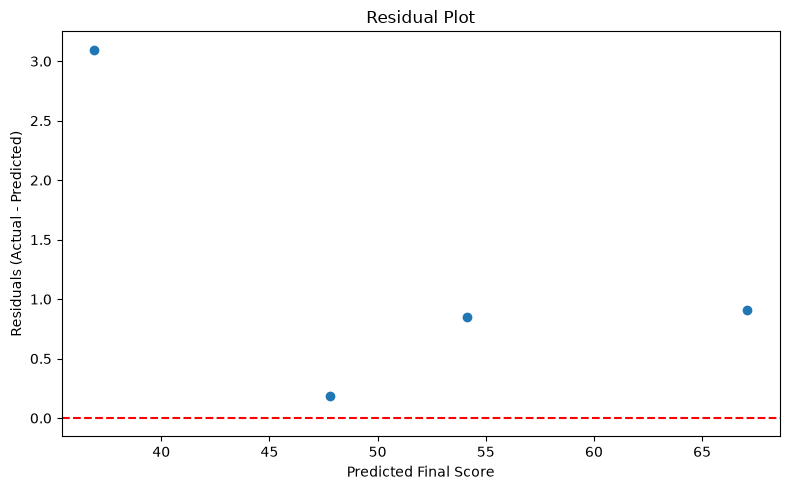

In [9]:
# Residual Analysis

residuals = y_test - y_pred

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals)
plt.axhline(y=0, linestyle="--", color="red")
plt.xlabel("Predicted Final Score")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Plot")
plt.tight_layout()
plt.show()

In [10]:
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"R² Score: {r2:.4f}")
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")

R² Score: 0.9736
MAE: 1.2597
RMSE: 1.6708
